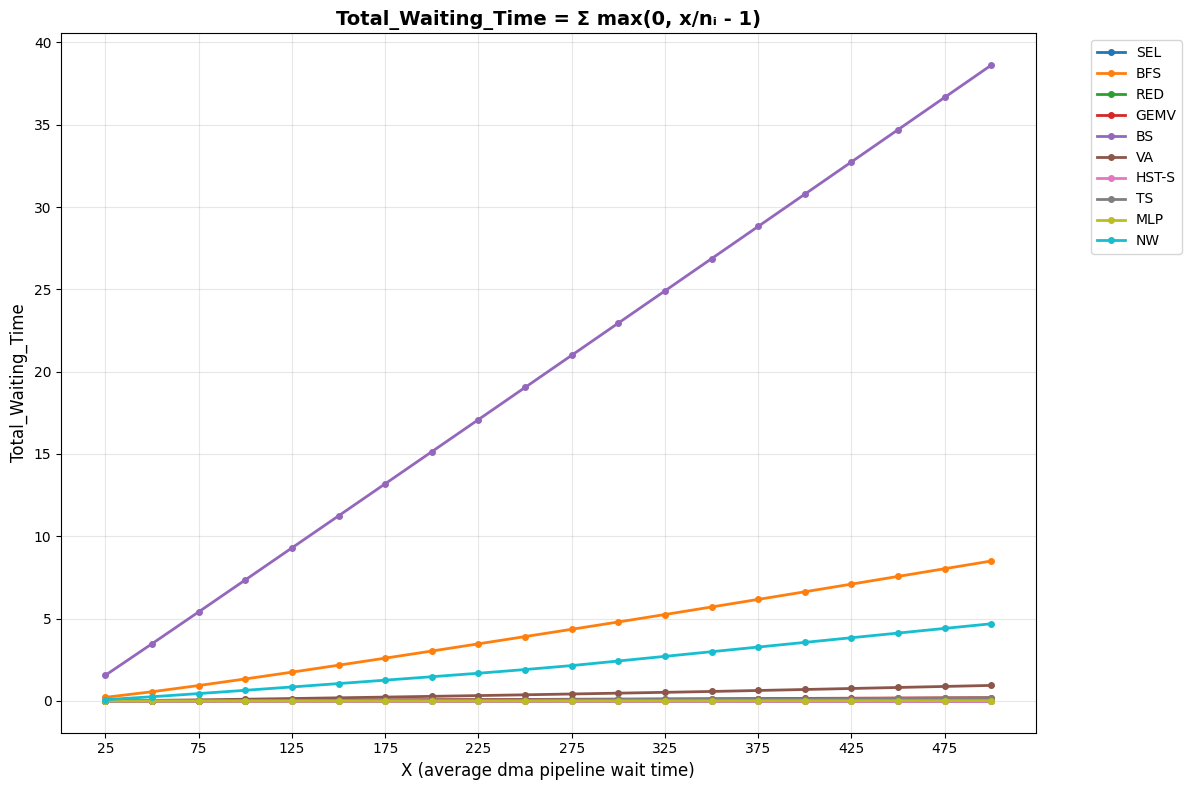


Threshold Analysis Results:
     SEL_output.txt  BFS_output.txt  RED_output.txt  GEMV_output.txt  \
25              0.0          0.2189          0.0042           0.0051   
50              0.0          0.5581          0.0103           0.0133   
75              0.0          0.9366          0.0164           0.0223   
100             0.0          1.3362          0.0225           0.0319   
125             0.0          1.7484          0.0286           0.0418   
150             0.0          2.1703          0.0347           0.0518   
175             0.0          2.5984          0.0408           0.0617   
200             0.0          3.0313          0.0469           0.0716   
225             0.0          3.4684          0.0530           0.0816   
250             0.0          3.9085          0.0591           0.0915   
275             0.0          4.3512          0.0652           0.1016   
300             0.0          4.7958          0.0713           0.1119   
325             0.0          5.2476

In [2]:
import pandas as pd
import numpy as np
import re
import os
from collections import Counter
import matplotlib.pyplot as plt

def read_txt_and_extract_start_times(txt_file_path):
    """Extract DMA start timestamps from text file"""
    try:
        with open(txt_file_path, 'r', encoding='utf-8') as file:
            lines = file.readlines()
        
        start_times = []
        pattern = r'start dma (\d+)'
        
        for line in lines:
            matches = re.findall(pattern, line, re.IGNORECASE)
            for match in matches:
                timestamp = int(match)
                start_times.append(timestamp)
        
        start_times.sort()
        return start_times
        
    except Exception as e:
        return []

def calculate_intervals(start_times):
    """Calculate time intervals between consecutive DMA start times"""
    if len(start_times) < 2:
        return []
    
    intervals = []
    for i in range(1, len(start_times)):
        interval = start_times[i] - start_times[i-1]
        intervals.append(interval)
    
    return intervals

def calculate_reciprocal_sum(intervals, threshold):
    """Calculate the total waiting time using the formula: sum(max(0, x/n_i - 1))"""
    if not intervals:
        return 0
    
    reciprocal_sum = 0
    
    for interval in intervals:
        if interval <= threshold and interval > 0:
            reciprocal_sum += (threshold / interval - 1)
    
    return reciprocal_sum / len(intervals)

def get_all_txt_files(folder_path):
    """Get all .txt files in the specified folder"""
    if not os.path.exists(folder_path):
        return []
    
    txt_files = [f for f in os.listdir(folder_path) if f.endswith('.txt')]
    return txt_files

def process_file_for_threshold(file_path, threshold):
    """Process a single file for a specific threshold value"""
    start_times = read_txt_and_extract_start_times(file_path)
    if not start_times:
        return 0
    
    intervals = calculate_intervals(start_times)
    if not intervals:
        return 0
    
    return calculate_reciprocal_sum(intervals, threshold)

def analyze_threshold_variation(folder_path=".", threshold_range=None):
    """Analyze how results vary with different threshold values"""
    if threshold_range is None:
        threshold_range = range(25, 501, 25)  # From 25 to 500, step 25 (avoid division by zero)
    
    txt_files = get_all_txt_files(folder_path)
    if not txt_files:
        return {}
    
    results = {}
    
    # Calculate results for each file under different threshold values
    for filename in txt_files:
        file_path = os.path.join(folder_path, filename)
        results[filename] = []
        
        for threshold in threshold_range:
            reciprocal_sum = process_file_for_threshold(file_path, threshold)
            results[filename].append(reciprocal_sum)
    
    return results, list(threshold_range)

def plot_threshold_analysis(results, thresholds, folder_path=".", save_plot=True, save_path="dma_analysis_plot.png"):
    """Plot the threshold analysis results"""
    plt.figure(figsize=(12, 8))
    
    # Draw lines for each file
    for filename, values in results.items():
        plt.plot(thresholds, values, marker='o', linewidth=2, markersize=4, label=filename.split('_')[0])
    
    plt.xlabel('X (average dma pipeline wait time)', fontsize=12)
    plt.ylabel('Total_Waiting_Time', fontsize=12)
    plt.title('Total_Waiting_Time = Σ max(0, x/nᵢ - 1)', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    # Set x-axis ticks
    plt.xticks(thresholds[::2])  # Show every other tick to avoid crowding
    
    plt.tight_layout()
    
    # Save the plot
    if save_plot:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')
    
    plt.show()
    
    # Print numerical table
    print("\nThreshold Analysis Results:")
    print("=" * 80)
    
    # Create DataFrame for better visualization
    df = pd.DataFrame(results, index=thresholds)
    print(df.round(4))
    
    # Calculate sum trends
    total_sums = [sum(results[filename][i] for filename in results.keys()) 
                  for i in range(len(thresholds))]
    
    for i, threshold in enumerate(thresholds):
        print(f"Threshold {threshold:3d}: sum = {total_sums[i]:8.4f}")

def main():
    """Main function to execute the analysis"""
    folder_path = "."
    
    # Analyze threshold variation from 25 to 500 (avoid division by zero when threshold=0)
    results, thresholds = analyze_threshold_variation(folder_path)
    
    if results:
        plot_threshold_analysis(results, thresholds, folder_path)
    else:
        assert False

def analyze_custom_range(folder_path=".", start=25, end=500, step=25, save_plot=True, save_path="dma_custom_analysis.png"):
    """Analyze custom threshold range"""
    threshold_range = range(start, end+1, step)
    results, thresholds = analyze_threshold_variation(folder_path, threshold_range)
    
    if results:
        plot_threshold_analysis(results, thresholds, folder_path, save_plot, save_path)
    else:
        assert False

if __name__ == "__main__":
    main()